# Week 7 – Dimensionality Reduction

**Continuation of DSV_team2_Week_6 (Feature Engineering)**

Dimensionality reduction helps:
- **Reduce feature space** — Fewer features mean faster training and less overfitting
- **Remove redundancy** — Highly correlated features add noise without new information
- **Improve model efficiency** — Smaller datasets are easier to visualize and deploy

This week we apply **correlation-based feature selection**, **VarianceThreshold**, **SelectKBest**, and **PCA**.

## 1. Import Libraries

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold

import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.facecolor'] = 'white'

## 2. Load Processed Dataset

In [31]:
import pandas as pd
import os
# File path
file_path = "/Users/manojmj/Downloads/flight_delay_cleaned.csv"
# Load dataset
if os.path.exists(file_path):
    df = pd.read_csv(file_path)
    print("Loaded: flight_delay_cleaned.csv")
else:
    raise FileNotFoundError("Dataset file not found in the specified path.")

# Display dataset info
print("\nDataset Shape:", df.shape)
df.head()

Loaded: flight_delay_cleaned.csv

Dataset Shape: (1669746, 26)


,YEAR,MONTH,DAY_OF_MONTH,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,ORIGIN,ORIGIN_CITY_NAME,DEST_AIRPORT_ID,...,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,CANCELLED,DIVERTED,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
0,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,832,757.0,-35.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2024,1,1,9E,10135,1013506,30135,ABE,"Allentown/Bethlehem/Easton, PA",10397,...,1450,1437.0,-13.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,850,821.0,-29.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2024,1,1,9E,10185,1018502,30185,AEX,"Alexandria, LA",10397,...,1917,1851.0,-26.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2024,1,1,9E,10208,1020803,30208,AGS,"Augusta, GA",10397,...,2010,1947.0,-23.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1669746 entries, 0 to 1669745
Data columns (total 26 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   YEAR                   1669746 non-null  int64  
 1   MONTH                  1669746 non-null  int64  
 2   DAY_OF_MONTH           1669746 non-null  int64  
 3   OP_UNIQUE_CARRIER      1669746 non-null  object 
 4   ORIGIN_AIRPORT_ID      1669746 non-null  int64  
 5   ORIGIN_AIRPORT_SEQ_ID  1669746 non-null  int64  
 6   ORIGIN_CITY_MARKET_ID  1669746 non-null  int64  
 7   ORIGIN                 1669746 non-null  object 
 8   ORIGIN_CITY_NAME       1669746 non-null  object 
 9   DEST_AIRPORT_ID        1669746 non-null  int64  
 10  DEST_AIRPORT_SEQ_ID    1669746 non-null  int64  
 11  DEST_CITY_MARKET_ID    1669746 non-null  int64  
 12  DEST                   1669746 non-null  object 
 13  CRS_DEP_TIME           1669746 non-null  int64  
 14  DEP_TIME          

In [33]:
df.describe()

,YEAR,MONTH,DAY_OF_MONTH,ORIGIN_AIRPORT_ID,ORIGIN_AIRPORT_SEQ_ID,ORIGIN_CITY_MARKET_ID,DEST_AIRPORT_ID,DEST_AIRPORT_SEQ_ID,DEST_CITY_MARKET_ID,CRS_DEP_TIME,...,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,CANCELLED,DIVERTED,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
count,1669746.0,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06,...,1.669746e+06,1.669746e+06,1.669746e+06,1669746.0,1669746.0,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06,1.669746e+06
mean,2024.0,6.278432e+00,1.596792e+01,1.264842e+04,1.264846e+06,3.173422e+04,1.265041e+04,1.265045e+06,3.173788e+04,1.319452e+03,...,1.482428e+03,1.459894e+03,1.319243e-01,0.0,0.0,3.015734e+00,1.753890e-01,1.447803e+00,2.910622e-04,3.471848e+00
std,0.0,3.670148e+00,9.008459e+00,1.533276e+03,1.533274e+05,1.324145e+03,1.533697e+03,1.533695e+05,1.325568e+03,4.921604e+02,...,5.177538e+02,5.353104e+02,2.618225e+01,0.0,0.0,1.234366e+01,2.298438e+00,5.773131e+00,2.993093e-02,1.322187e+01
min,2024.0,1.000000e+00,1.000000e+00,1.013500e+04,1.013506e+06,3.007000e+04,1.013500e+04,1.013506e+06,3.007000e+04,1.000000e+00,...,1.000000e+00,1.000000e+00,-9.100000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2024.0,1.000000e+00,8.000000e+00,1.129200e+04,1.129202e+06,3.061500e+04,1.129200e+04,1.129202e+06,3.061500e+04,9.000000e+02,...,1.059000e+03,1.043000e+03,-1.600000e+01,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2024.0,7.000000e+00,1.600000e+01,1.288900e+04,1.288904e+06,3.145300e+04,1.288900e+04,1.288904e+06,3.145300e+04,1.312000e+03,...,1.508000e+03,1.458000e+03,-7.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2024.0,1.000000e+01,2.400000e+01,1.405700e+04,1.405702e+06,3.246700e+04,1.405700e+04,1.405702e+06,3.252300e+04,1.730000e+03,...,1.917000e+03,1.912000e+03,7.000000e+00,0.0,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,2024.0,1.000000e+01,3.100000e+01,1.686900e+04,1.686902e+06,3.599100e+04,1.686900e+04,1.686902e+06,3.599100e+04,2.359000e+03,...,2.359000e+03,2.400000e+03,1.940000e+02,0.0,0.0,1.240000e+02,5.200000e+01,4.700000e+01,4.000000e+00,1.060000e+02


## 3. Check Feature Correlation

**Why remove correlated features?**
- Multicollinearity inflates variance in regression models
- Redundant features add computational cost without information gain
- PCA performs better when underlying features are less correlated (after removing extreme duplicates)

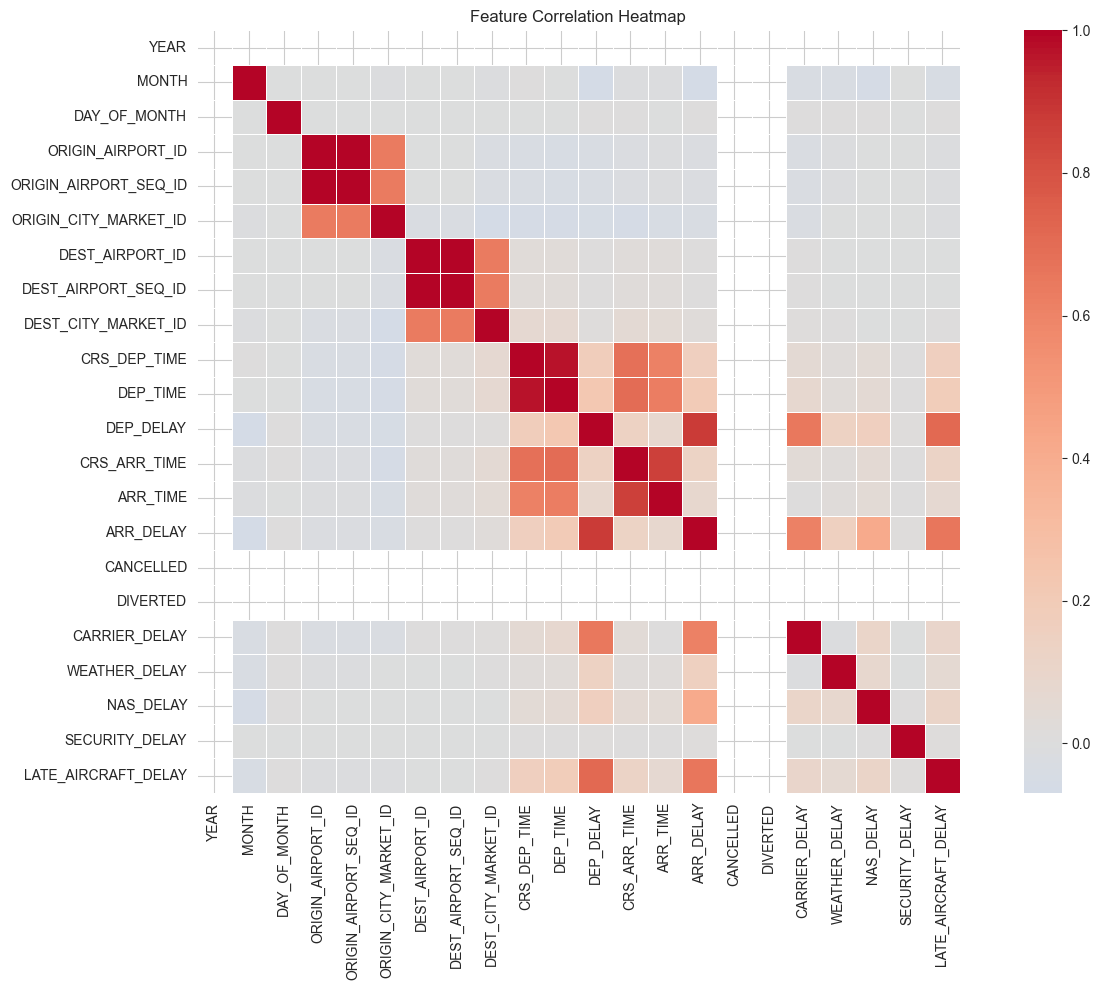

In [34]:
# Use only numeric columns for correlation
df_numeric = df.select_dtypes(include=[np.number])
corr = df_numeric.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, fmt='.2f')
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [35]:
# Identify highly correlated features (|r| > 0.9)
threshold = 0.9
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_pairs = [(col, upper[col][upper[col].abs() > threshold].index.tolist()) 
                   for col in upper.columns if any(upper[col].abs() > threshold)]

print('Highly correlated feature pairs (|r| > 0.9):')
for feat, correlated in high_corr_pairs:
    print(f'  {feat} <-> {correlated}')

Highly correlated feature pairs (|r| > 0.9):
  ORIGIN_AIRPORT_SEQ_ID <-> ['ORIGIN_AIRPORT_ID']
  DEST_AIRPORT_SEQ_ID <-> ['DEST_AIRPORT_ID']
  DEP_TIME <-> ['CRS_DEP_TIME']


## 4. Feature Selection

We apply three techniques:
1. **Variance Threshold** — Remove near-constant features
2. **Correlation-based removal** — Drop redundant correlated columns
3. **SelectKBest (ANOVA F-test)** — Select top K features by statistical significance

In [36]:
# --- 1) Variance Threshold ---
var_threshold = 0.01
selector_var = VarianceThreshold(threshold=var_threshold)
selector_var.fit(df_numeric)
cols_after_var = df_numeric.columns[selector_var.get_support()]
df_after_var = df_numeric[cols_after_var]

print(f'Variance Threshold ({var_threshold}):')
print(f'  Removed: {len(df_numeric.columns) - len(cols_after_var)} low-variance columns')
print(f'  Remaining: {len(cols_after_var)} features')

Variance Threshold (0.01):
  Removed: 4 low-variance columns
  Remaining: 18 features


In [37]:
# --- 2) Correlation-based removal ---
to_drop = [column for column in upper.columns if any(upper[column].abs() > threshold)]
cols_after_corr = [c for c in df_after_var.columns if c not in to_drop]
df_after_corr = df_after_var[cols_after_corr]

print(f'\nCorrelation-based removal (r > {threshold}):')
print(f'  Dropped: {to_drop}')
print(f'  Remaining: {len(cols_after_corr)} features')


Correlation-based removal (r > 0.9):
  Dropped: ['ORIGIN_AIRPORT_SEQ_ID', 'DEST_AIRPORT_SEQ_ID', 'DEP_TIME']
  Remaining: 15 features


In [38]:
# --- 3) SelectKBest (ANOVA F-test) ---
# Use CANCELLED or first binary/categorical column as target if available
target_candidates = ['CANCELLED', 'target', 'label', 'class', 'Target', 'Label', 'Class']
target_col = None
for tc in target_candidates:
    if tc in df_after_corr.columns:
        target_col = tc
        break

if target_col is not None:
    X_sel = df_after_corr.drop(columns=[target_col])
    y_sel = df_after_corr[target_col]
    k_best = min(15, X_sel.shape[1])  # Top 15 or all if fewer
    selector_k = SelectKBest(score_func=f_classif, k=k_best)
    selector_k.fit(X_sel, y_sel)
    selected_mask = selector_k.get_support()
    selected_features = X_sel.columns[selected_mask].tolist()
    df_selected = df_after_corr[selected_features + [target_col]]
    print(f'\nSelectKBest (k={k_best}, target={target_col}):')
else:
    selected_features = cols_after_corr
    df_selected = df_after_corr
    print('\nSelectKBest: No target column found. Using correlation-filtered features.')


SelectKBest: No target column found. Using correlation-filtered features.


In [39]:
print('\nSelected feature names:', selected_features)


Selected feature names: ['MONTH', 'DAY_OF_MONTH', 'ORIGIN_AIRPORT_ID', 'ORIGIN_CITY_MARKET_ID', 'DEST_AIRPORT_ID', 'DEST_CITY_MARKET_ID', 'CRS_DEP_TIME', 'DEP_DELAY', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'LATE_AIRCRAFT_DELAY']


## 5. Feature Scaling

In [40]:
# 5. Feature Scaling (REVERTED TO STANDARD SCALER)
from sklearn.preprocessing import StandardScaler

# PREVENT DATA LEAKAGE: Hide the answers (Delays) from the PCA algorithm
targets_to_exclude = ['ARR_DELAY', 'DEP_DELAY', 'DEP_DELAY_CBRT']
feature_cols = [c for c in df_selected.columns if c not in targets_to_exclude]

# Save the target column safely on the side for later
y_target = df_selected['ARR_DELAY'] if 'ARR_DELAY' in df_selected.columns else None

X = df_selected[feature_cols]

# CHANGED BACK: Use StandardScaler for optimal PCA variance detection
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print('Features successfully scaled with StandardScaler.')
print('Target variables strictly excluded to prevent data leakage.')
print(f'Feature matrix shape: {X_scaled.shape}')

Features successfully scaled with StandardScaler.
Target variables strictly excluded to prevent data leakage.
Feature matrix shape: (1669746, 13)


## 6. Principal Component Analysis (PCA)

In [41]:
n_components_full = min(X_scaled.shape[0], X_scaled.shape[1])
pca = PCA(n_components=n_components_full)
pca.fit(X_scaled)
print('Explained variance ratio (first 15 components):')
for i, v in enumerate(pca.explained_variance_ratio_[:15], 1):
    print(f'  PC{i}: {v:.4f} ({v*100:.2f}%)')

Explained variance ratio (first 15 components):
  PC1: 0.1929 (19.29%)
  PC2: 0.1289 (12.89%)
  PC3: 0.1213 (12.13%)
  PC4: 0.0947 (9.47%)
  PC5: 0.0781 (7.81%)
  PC6: 0.0769 (7.69%)
  PC7: 0.0746 (7.46%)
  PC8: 0.0684 (6.84%)
  PC9: 0.0663 (6.63%)
  PC10: 0.0320 (3.20%)
  PC11: 0.0286 (2.86%)
  PC12: 0.0273 (2.73%)
  PC13: 0.0099 (0.99%)


In [42]:
# Optimal number of components for ~90–95% variance
cumulative_var = np.cumsum(pca.explained_variance_ratio_)
n_90 = np.argmax(cumulative_var >= 0.90) + 1
n_95 = np.argmax(cumulative_var >= 0.95) + 1
print(f'Components for 90% variance: {n_90}')
print(f'Components for 95% variance: {n_95}')

Components for 90% variance: 9
Components for 95% variance: 11


## 7. Explained Variance Visualization

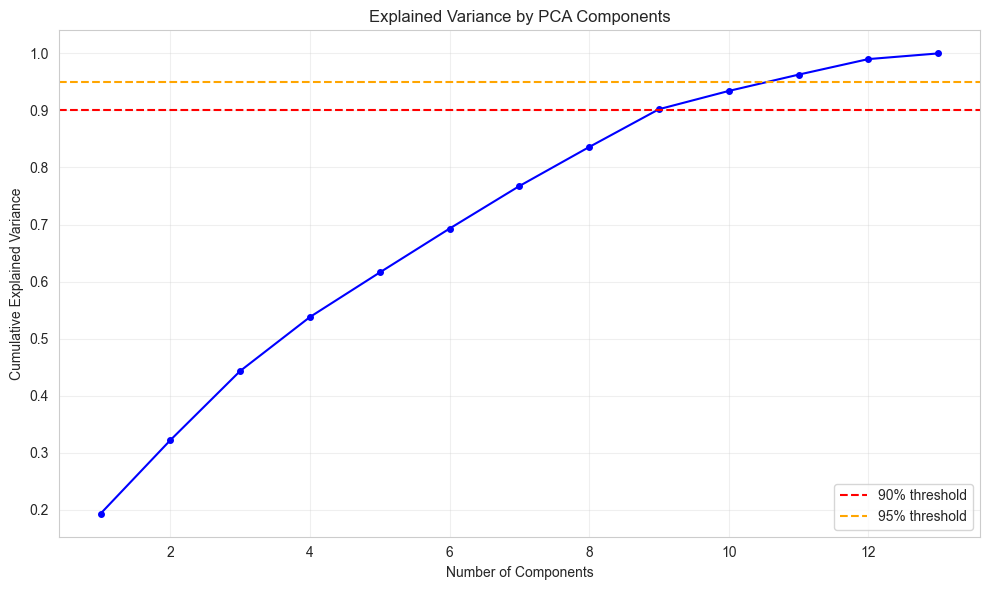

In [43]:
plt.figure(figsize=(10, 6))
n_show = min(50, len(cumulative_var))
x = np.arange(1, n_show + 1)
plt.plot(x, cumulative_var[:n_show], 'b-o', markersize=4)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% threshold')
plt.axhline(y=0.95, color='orange', linestyle='--', label='95% threshold')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by PCA Components')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. PCA Projection Visualization (2D)

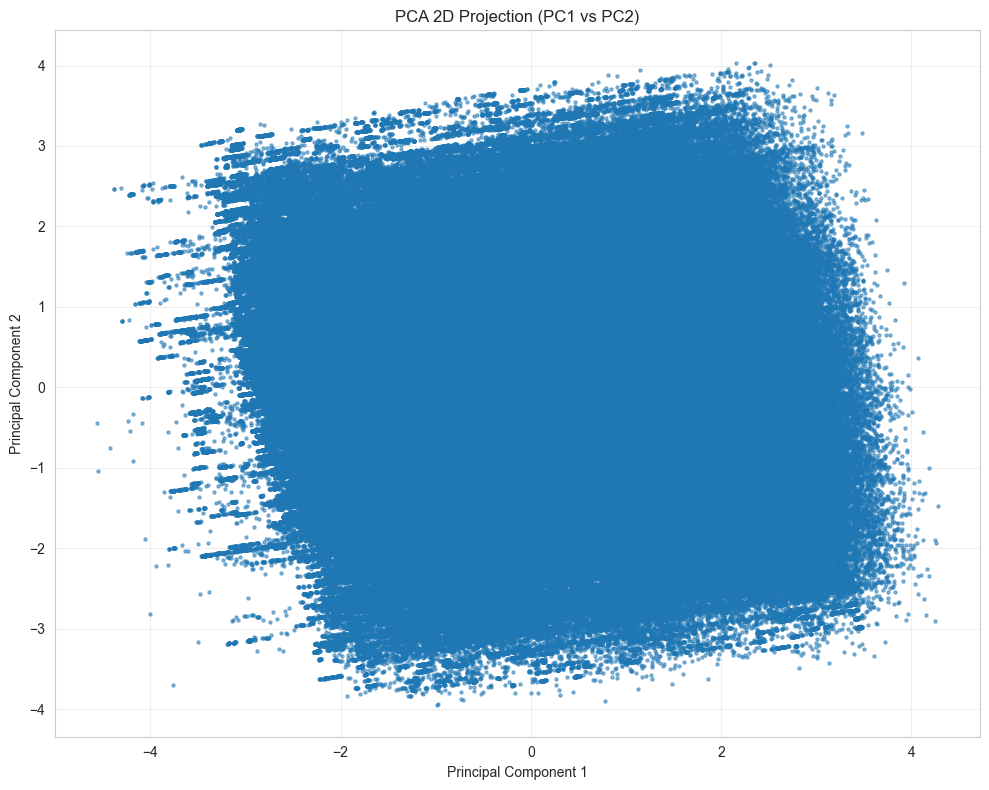

In [44]:
pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X_scaled)

plt.figure(figsize=(10, 8))
if target_col and target_col in df_selected.columns:
    y_plot = df_selected[target_col]
    scatter = plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=y_plot, cmap='viridis', alpha=0.5, s=5)
    plt.colorbar(scatter, label=target_col)
else:
    plt.scatter(X_pca2[:, 0], X_pca2[:, 1], alpha=0.5, s=5)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA 2D Projection (PC1 vs PC2)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. PCA Loadings Analysis (Advanced)

In [45]:
# Loadings: contribution of each original feature to each PC
loadings = pd.DataFrame(
    pca2.components_.T,
    columns=['PC1', 'PC2'],
    index=feature_cols
)
loadings['abs_PC1'] = loadings['PC1'].abs()
loadings = loadings.sort_values('abs_PC1', ascending=False)

print('Top features contributing to PC1 (by absolute loading):')
display(loadings[['PC1', 'PC2']].head(10))

Top features contributing to PC1 (by absolute loading):


,PC1,PC2
CRS_ARR_TIME,0.587421,0.103637
ARR_TIME,0.566242,0.109985
CRS_DEP_TIME,0.526674,0.066340
LATE_AIRCRAFT_DELAY,0.142419,0.026018
DEST_CITY_MARKET_ID,0.096924,-0.497268
ORIGIN_CITY_MARKET_ID,-0.093170,0.507912
DEST_AIRPORT_ID,0.071082,-0.476022
NAS_DELAY,0.068481,0.021721
ORIGIN_AIRPORT_ID,-0.065978,0.488459
CARRIER_DELAY,0.054543,-0.033880


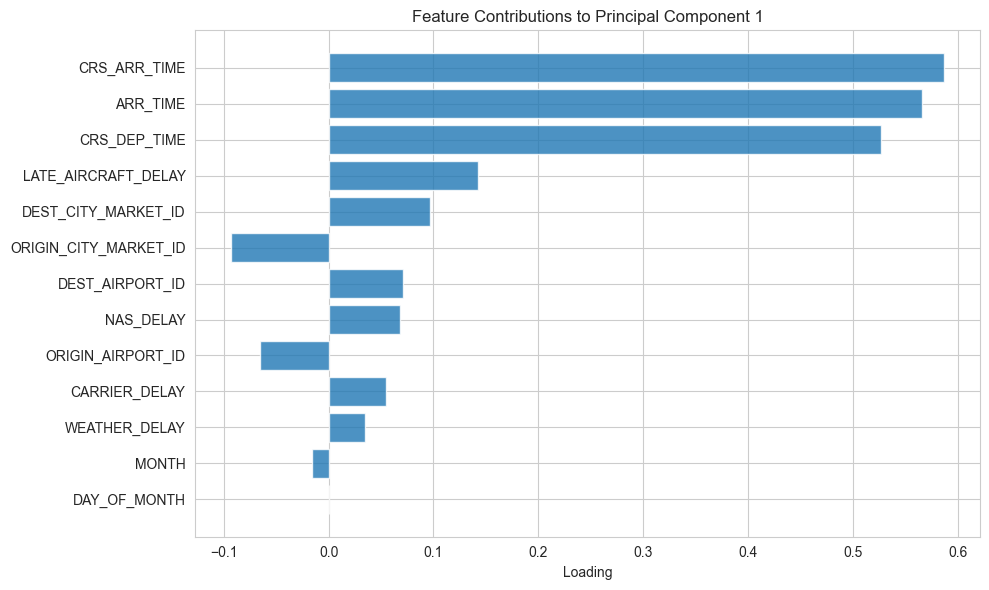

In [46]:
plt.figure(figsize=(10, 6))
top_n = min(15, len(loadings))
load_top = loadings.head(top_n)
x_pos = np.arange(len(load_top))
plt.barh(x_pos, load_top['PC1'].values, label='PC1', alpha=0.8)
plt.yticks(x_pos, load_top.index)
plt.xlabel('Loading')
plt.title('Feature Contributions to Principal Component 1')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Final Reduced Dataset

In [47]:
import numpy as np
from sklearn.decomposition import PCA

# Fit PCA on all components first to find the variance ratio
pca_temp = PCA()
pca_temp.fit(X_scaled)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca_temp.explained_variance_ratio_)

# Find the number of components needed for 90% variance
n_90 = np.argmax(cumulative_variance >= 0.90) + 1

print(f"Number of components for 90% variance: {n_90}")


Number of components for 90% variance: 9


In [48]:
# Cell 1
pca_final = PCA(n_components=0.90)
X_pca_final = pca_final.fit_transform(X_scaled)  # <--- This is where X_pca_final is created!
# Cell 2
import pandas as pd
pc_columns = [f'PC{i+1}' for i in range(X_pca_final.shape[1])]
df_reduced = pd.DataFrame(data=X_pca_final, columns=pc_columns)  # <--- This is where df_reduced is created!
# Cell 3
df_reduced.to_csv('reduced_features_week7.csv', index=False)
print(f'Saved: reduced_features_week7.csv')
print(f'Shape: {df_reduced.shape}')


Saved: reduced_features_week7.csv
Shape: (1669746, 9)


## 11. Conclusion

**Feature Selection Results:**
- Variance Threshold removed near-constant features
- Correlation-based removal dropped highly correlated pairs (|r| > 0.9)
- SelectKBest (ANOVA F-test) selected top features by predictive power

**PCA Dimensionality Reduction:**
- Reduced features to principal components explaining ~90–95% variance
- Loadings show which original features contribute most to each component

**Variance Retained:** Approximately 90% with fewer components than original features.

**Benefits for Modeling:**
- Faster training and inference
- Reduced overfitting risk
- Ready for Week 8 dashboard building and visualization